# Comparison of the two $\Delta\Delta G_{bind}$ calculation methods

FEP gives $\Delta\Delta G$ directly only for the edges of the perturbation graph.
All pairwise values can be obtained in two ways:

1. **graph**: sum the signed edge weights along all shortest paths between the pair
   (averaging when several shortest paths exist) - the approach used in this work;
2. **fitted**: the absolute $\Delta G$ values reported by Hahn et al.,
   which were obtained by a maximum-likelihood fit over the same graph.

This notebook computes both for every compound pair and plots the distribution of
their difference ($\Delta\Delta\Delta G$). Produces `GRAPH_OFF.png` and `GRAPH_OPLS.png`.

General note: ligand ids and pair names repeat across targets, so every lookup here is keyed
on **(target, pair)**. Matching on the name alone silently mixes targets.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LIGANDS = "../../../../0_DATA/HAHN/03b_all_ligands_all_ffs.csv"
GRAPH = {"OFF":  ("../OFF/OPENFF_FEP_DDG_FROM_GRAPH.csv",  "DG_OpenFF-2.0", "OpenFF-2.0"),
         "OPLS": ("../OPLS/OPLS_FEP_DDG_FROM_GRAPH.csv",   "DG_OPLS3e",     "OPLS3e")}

ligs = pd.read_csv(LIGANDS)
print(ligs.shape, "ligand rows")

(598, 31) ligand rows


In [2]:
def fitted_pairwise(dg_column):
    """All pairwise ddG from Hahn's fitted dG values, keyed on (target, pair)."""
    rows = []
    for target, grp in ligs.groupby("target"):
        vals = dict(zip(grp["ligand"].astype(str), grp[dg_column]))
        for a, b in itertools.combinations(sorted(vals), 2):
            if np.isnan(vals[a]) or np.isnan(vals[b]):
                continue
            rows.append({"target": target,
                         "pair": f"lig_{a}__lig_{b}",
                         "DDG_fitted": vals[b] - vals[a]})
    return pd.DataFrame(rows)

In [3]:
results = {}
for tag, (graph_csv, dg_col, label) in GRAPH.items():
    # graph route: one row per shortest path -> collapse to one value per (target, pair)
    g = (pd.read_csv(graph_csv)
           .groupby(["target", "pair"], as_index=False)
           .agg(DDG_graph=("DDG", "mean"), n_values=("DDG", "nunique")))
    assert g["n_values"].max() == 1, "several distinct DDG values within one (target, pair)"

    f = fitted_pairwise(dg_col)

    # merge on (target, pair): matching on pair alone would mix targets and mess up results
    m = g.merge(f, on=["target", "pair"], how="inner", validate="one_to_one")
    m["DDDG"] = m["DDG_graph"] - m["DDG_fitted"]
    results[tag] = m
    print(f"{label:12s} pairs compared: {len(m):6d}   "
          f"mean {m.DDDG.mean():+.3f}   sd {m.DDDG.std():.3f}   "
          f"max |DDDG| {m.DDDG.abs().max():.2f} kcal/mol")

OpenFF-2.0   pairs compared:   8994   mean +0.042   sd 0.981   max |DDDG| 10.82 kcal/mol
OPLS3e       pairs compared:   8994   mean +0.007   sd 0.529   max |DDDG| 5.19 kcal/mol


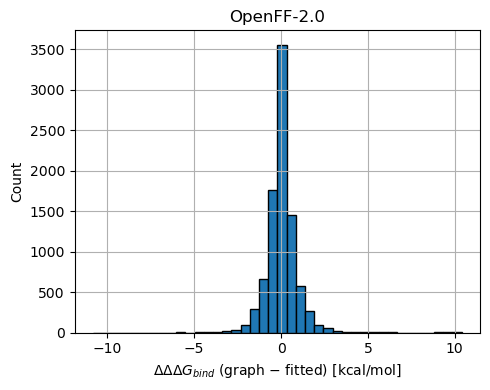

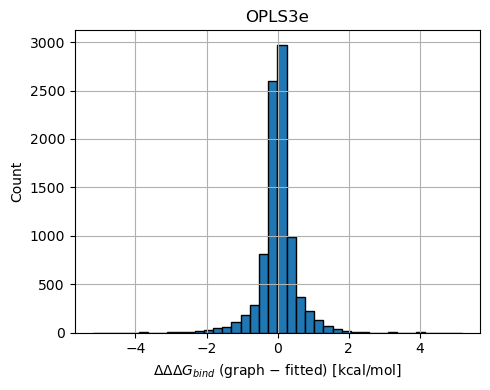

In [4]:
for tag, (_, _, label) in GRAPH.items():
    m = results[tag]
    plt.figure(figsize=(5, 4))
    m["DDDG"].hist(bins=40, edgecolor="black")
    plt.xlabel(r"$\Delta\Delta\Delta G_{bind}$ (graph $-$ fitted) [kcal/mol]")
    plt.ylabel("Count")
    plt.title(label)
    plt.tight_layout()
    plt.savefig(f"GRAPH_{tag}.png", dpi=300)
    plt.show()

In [5]:
# fraction of pairs where the two routes disagree by more than 1 kcal/mol
for tag, (_, _, label) in GRAPH.items():
    m = results[tag]
    for thr in (1.0, 3.0):
        n = (m.DDDG.abs() > thr).sum()
        print(f"{label:12s} |DDDG| > {thr} kcal/mol: {n:5d} / {len(m)}  ({100*n/len(m):.2f} %)")

OpenFF-2.0   |DDDG| > 1.0 kcal/mol:  1666 / 8994  (18.52 %)
OpenFF-2.0   |DDDG| > 3.0 kcal/mol:   127 / 8994  (1.41 %)
OPLS3e       |DDDG| > 1.0 kcal/mol:   612 / 8994  (6.80 %)
OPLS3e       |DDDG| > 3.0 kcal/mol:    24 / 8994  (0.27 %)
